<a href="https://colab.research.google.com/github/ZackyRioOrlando/Praktikum-Pembelajaran-Mesin-/blob/main/JS08/JS08_Tugas_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🎗️
Tugas Lab 1

- Gunakan dataset CC_Customer_Dataset.csv dari Tugas Lab

- Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

- Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

- Tentukan nilai silhouette score dan DBI dari model.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv


Langkah 2 - Import library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

Langkah 3 - Membaca dataset

In [3]:
df = pd.read_csv('CC_Customer_Dataset.csv')

df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Periksa ukuran dataset:

In [4]:
print("Ukuran Dataset:", df.shape)
print("\nInformasi Dataset:")
df.info()

print("\nJumlah Missing Value:")
print(df.isnull().sum())

Ukuran Dataset: (660, 7)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah Missing Value:
Sl_No                  0
Customer Key           0
Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
dtype: int64


Langkah 4 - Memilih seluruh variabel untuk klasterisasi

In [5]:
X = df[['Avg_Credit_Limit',
        'Total_Credit_Cards',
        'Total_visits_bank',
        'Total_visits_online',
        'Total_calls_made']]

X.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


Langkah 5 - Normalisasi data

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Hasil Normalisasi:")
print(X_scaled[:5])

Hasil Normalisasi:
[[ 1.74018685 -1.24922476 -0.86045063 -0.54748969 -1.25153737]
 [ 0.41029254 -0.78758515 -1.47373077  2.5205186   1.89185881]
 [ 0.41029254  1.05897329 -0.86045063  0.13428993  0.1455276 ]
 [-0.12166518  0.13569407 -0.86045063 -0.54748969  0.1455276 ]
 [ 1.74018685  0.59733368 -1.47373077  3.20229822 -0.20373864]]


Langkah 6 - Membuat model Agglomerative Clustering

In [7]:
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

labels = model.fit_predict(X_scaled)

df['Cluster'] = labels

print("Hasil Clustering:")
print(df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Cluster']].head(10))

Hasil Clustering:
   Avg_Credit_Limit  Total_Credit_Cards  Cluster
0            100000                   2        0
1             50000                   3        1
2             50000                   7        0
3             30000                   5        0
4            100000                   6        2
5             20000                   3        1
6            100000                   5        2
7             15000                   3        1
8              5000                   2        1
9              3000                   4        1


Langkah 7 - Membuat scatterplot berdasarkan dua variabel

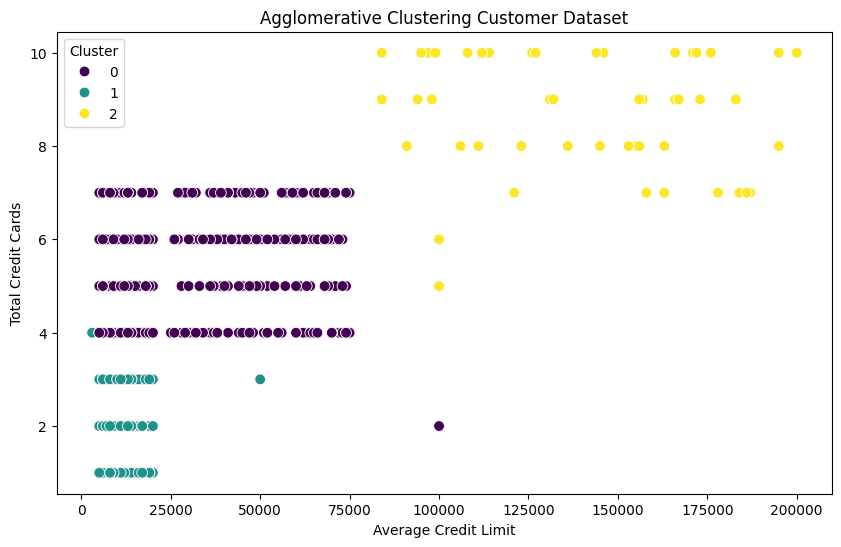

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Agglomerative Clustering Customer Dataset')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.show()

Langkah 8 - Menghitung Silhouette Score

In [9]:
silhouette = silhouette_score(X_scaled, labels)

print("Silhouette Score:", silhouette)

Silhouette Score: 0.5147639589977819


Langkah 9 - Menghitung Davies-Bouldin Index (DBI)

In [10]:
dbi = davies_bouldin_score(X_scaled, labels)

print("Davies-Bouldin Index:", dbi)

Davies-Bouldin Index: 0.680959518994733


Langkah 10 - Menampilkan hasil evaluasi

In [11]:
print("=== HASIL EVALUASI AGGLOMERATIVE CLUSTERING ===")
print("Jumlah Cluster:", len(np.unique(labels)))
print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", dbi)

print("\nJumlah Data Setiap Cluster:")
print(df['Cluster'].value_counts().sort_index())

=== HASIL EVALUASI AGGLOMERATIVE CLUSTERING ===
Jumlah Cluster: 3
Silhouette Score: 0.5147639589977819
Davies-Bouldin Index: 0.680959518994733

Jumlah Data Setiap Cluster:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64
